In [ ]:
 !pip install nbconvert[webpdf]

In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, norm, mannwhitneyu, kruskal, spearmanr, skew, kurtosis


In [5]:
df = pd.read_csv("Nigerian_Election_Dataset_clean.csv")
df.head(10)

,AgeGroup,Gender,Zone,HighestEducation,EmploymentStatus,MonthlyPersonalIncome,Q8_Understanding,Q10_INEC_Fair,Q6_Transparency,Q9_TrustCount,...,Q26_AcceptingMoneySurvival,Q27_SellingJustified,Q28_VoteForFinancialAssistance,Q29_LackAccountabilityEncouragesVoteSelling,Q30_ChooseCandidatesCompetence,Q31_RelyOnLeaders,Q32_ResearchCandidates,Q33_GiftsMoreLikelyWin,Q34_PeopleNoTrustElections,Target
0,26 - 35,Female,North Central,Secondary school certificate,Formal full-time,"Less than ₦20,000",2,2,2,1,...,5,3,5,2,5,3,2,3,3,0
1,60+,Male,North Central,Secondary school certificate,Formal full-time,"₦100,000 - ₦199,000",2,2,1,1,...,2,1,4,3,4,3,2,2,2,0
2,36 - 46,Female,North Central,Did not attend,Unemployed and looking,"₦100,000 - ₦199,000",1,1,1,1,...,2,1,2,3,4,4,4,3,4,1
3,26 - 35,Male,North West,Post Graduate,Unemployed and looking,"Less than ₦20,000",3,2,2,2,...,4,3,4,3,3,4,3,2,3,0
4,18 - 25,Female,North Central,Primary 6,Self-employed,"₦50,000 - ₦99,000",2,2,2,2,...,3,1,3,5,4,3,3,2,3,0
5,18 - 25,Male,South East,OND,Student,"₦100,000 - ₦199,000",2,2,1,1,...,4,2,3,2,2,3,4,2,4,0
6,18 - 25,Female,North West,Secondary school certificate,Student,"₦100,000 - ₦199,000",2,2,1,1,...,3,2,2,3,4,5,4,3,3,0
7,46 - 60,Female,North West,OND,Self-employed,"₦50,000 - ₦99,000",2,1,1,1,...,3,2,2,3,4,4,3,2,2,0
8,26 - 35,Female,North Central,B.Sc/HND/B.Eng,Student,"₦50,000 - ₦99,000",2,2,1,1,...,3,1,4,3,4,2,3,4,3,0
9,36 - 46,Male,South South,B.Sc/HND/B.Eng,Formal full-time,"₦50,000 - ₦99,000",3,2,1,2,...,3,1,3,4,5,3,3,3,3,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 444 entries, 0 to 443
Data columns (total 34 columns):
 #   Column                                       Non-Null Count  Dtype 
---  ------                                       --------------  ----- 
 0   AgeGroup                                     444 non-null    object
 1   Gender                                       444 non-null    object
 2   Zone                                         444 non-null    object
 3   HighestEducation                             444 non-null    object
 4   EmploymentStatus                             444 non-null    object
 5   MonthlyPersonalIncome                        444 non-null    object
 6   Q8_Understanding                             444 non-null    int64 
 7   Q10_INEC_Fair                                444 non-null    int64 
 8   Q6_Transparency                              444 non-null    int64 
 9   Q9_TrustCount                                444 non-null    int64 
 10  Q11_MaterialsA

In [7]:
df.describe(include='all')

,AgeGroup,Gender,Zone,HighestEducation,EmploymentStatus,MonthlyPersonalIncome,Q8_Understanding,Q10_INEC_Fair,Q6_Transparency,Q9_TrustCount,...,Q26_AcceptingMoneySurvival,Q27_SellingJustified,Q28_VoteForFinancialAssistance,Q29_LackAccountabilityEncouragesVoteSelling,Q30_ChooseCandidatesCompetence,Q31_RelyOnLeaders,Q32_ResearchCandidates,Q33_GiftsMoreLikelyWin,Q34_PeopleNoTrustElections,Target
count,444,444,444,444,444,444,444.000000,444.000000,444.000000,444.000000,...,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000
unique,5,3,6,6,6,6,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,18 - 25,Male,North West,Secondary school certificate,Formal full-time,"₦20,000 - ₦49,000",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,161,232,104,149,128,111,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,2.141892,1.743243,1.369369,1.425676,...,3.281532,1.885135,3.119369,3.380631,3.101351,3.004505,3.198198,3.022523,3.610360,0.421171
std,NaN,NaN,NaN,NaN,NaN,NaN,0.723767,0.571580,0.580774,0.499542,...,0.991850,0.719201,1.043818,0.894772,0.953122,0.943064,0.946132,1.045008,0.878117,0.739472
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,1.000000,1.000000,1.000000,...,3.000000,1.000000,2.000000,3.000000,2.000000,2.000000,3.000000,2.000000,3.000000,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,2.000000,1.000000,1.000000,...,3.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,0.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,2.000000,2.000000,2.000000,...,4.000000,2.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,1.000000


In [8]:
print(df.isna().sum())

AgeGroup                                       0
Gender                                         0
Zone                                           0
HighestEducation                               0
EmploymentStatus                               0
MonthlyPersonalIncome                          0
Q8_Understanding                               0
Q10_INEC_Fair                                  0
Q6_Transparency                                0
Q9_TrustCount                                  0
Q11_MaterialsAdequate                          0
Q12_INEC_onTime                                0
Q13_ViolenceCommon                             0
Q14_OfficersInfluence                          0
Q16_SafeParticipation                          0
Q17_VoteForState                               0
Q18_VoteForFriend                              0
Q19_Pressured                                  0
Q20_CampaignActiveDeserve                      0
Q21_GiftsShowCare                              0
Q22_ReceivingGiftsNo

In [9]:
# Identify numeric columns (Likert + Target)
numeric_cols = [col for col in df.columns if df[col].dtype != "object"]

# Compute skewness
skew_values = df[numeric_cols].apply(lambda x: skew(x, bias=False))

# Compute kurtosis (Fisher = True means normal distribution → kurtosis = 0)
kurtosis_values = df[numeric_cols].apply(lambda x: kurtosis(x, fisher=True, bias=False))

# Combine into one table
skew_kurt_df = pd.DataFrame({
    "Skewness": skew_values,
    "Kurtosis": kurtosis_values
})

print(skew_kurt_df)

                                             Skewness  Kurtosis
Q8_Understanding                            -0.185710 -0.999109
Q10_INEC_Fair                                0.060671 -0.448916
Q6_Transparency                              1.320142  0.738737
Q9_TrustCount                                0.356191 -1.738273
Q11_MaterialsAdequate                       -0.101648 -0.236345
Q12_INEC_onTime                              0.099776 -0.471721
Q13_ViolenceCommon                           0.200606 -0.441102
Q14_OfficersInfluence                       -0.082209 -0.466264
Q16_SafeParticipation                        0.209864 -0.444547
Q17_VoteForState                            -0.038596 -0.450864
Q18_VoteForFriend                            0.143661 -0.213404
Q19_Pressured                                0.052071 -0.618679
Q20_CampaignActiveDeserve                   -0.065927 -0.378175
Q21_GiftsShowCare                            0.031624 -0.609728
Q22_ReceivingGiftsNormal                

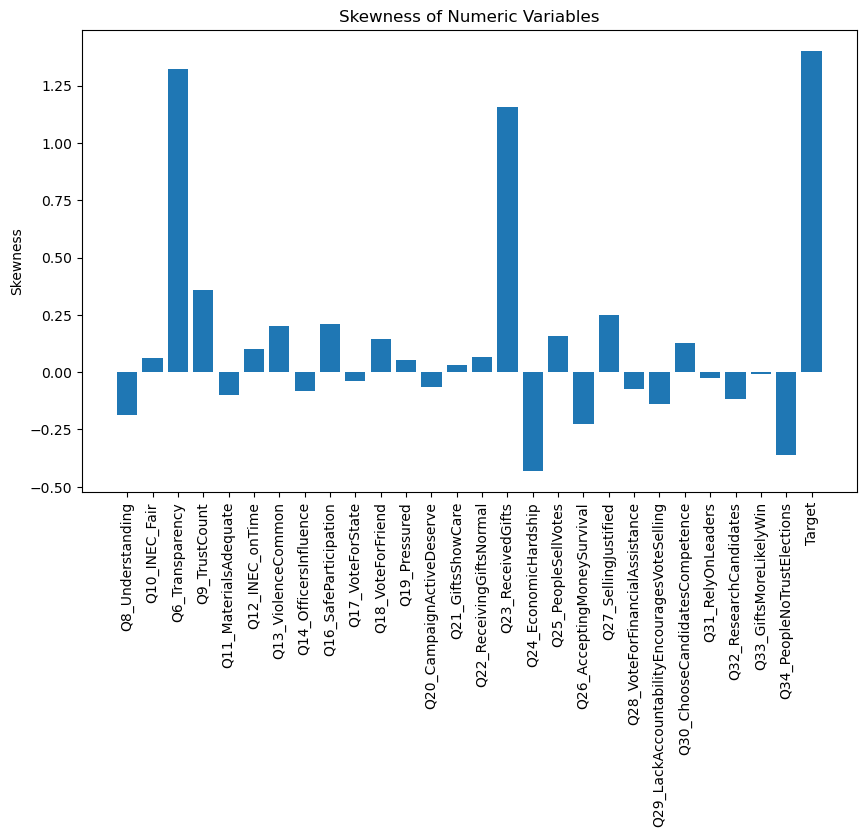

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.bar(skew_kurt_df.index, skew_kurt_df["Skewness"])
plt.xticks(rotation=90)
plt.title("Skewness of Numeric Variables")
plt.ylabel("Skewness")
plt.show()


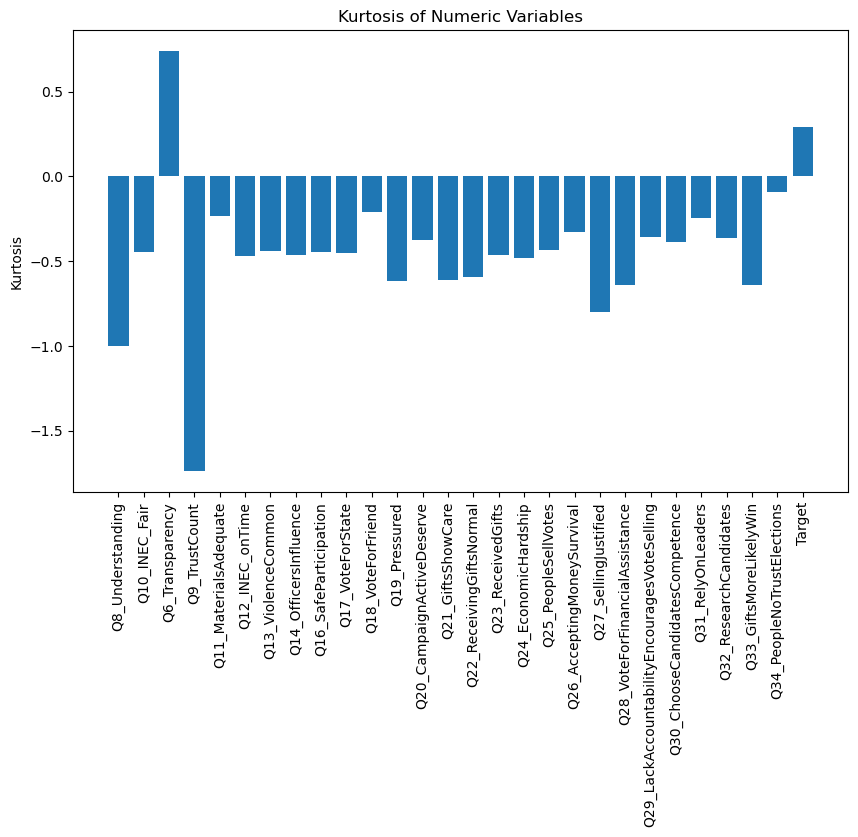

In [11]:
plt.figure(figsize=(10,6))
plt.bar(skew_kurt_df.index, skew_kurt_df["Kurtosis"])
plt.xticks(rotation=90)
plt.title("Kurtosis of Numeric Variables")
plt.ylabel("Kurtosis")
plt.show()


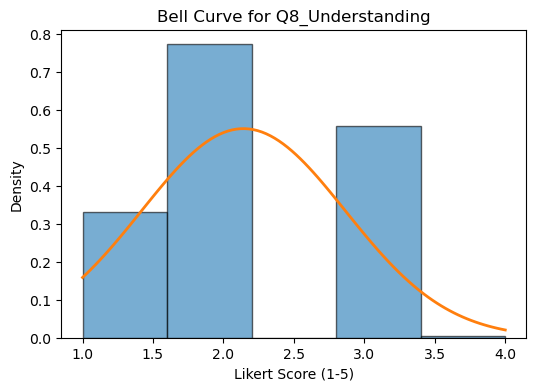

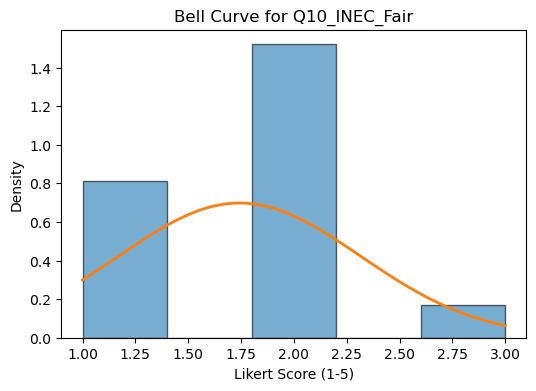

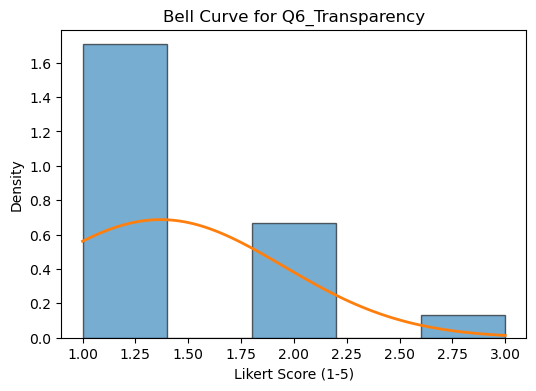

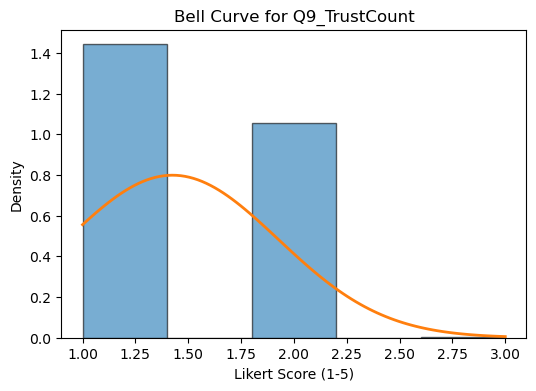

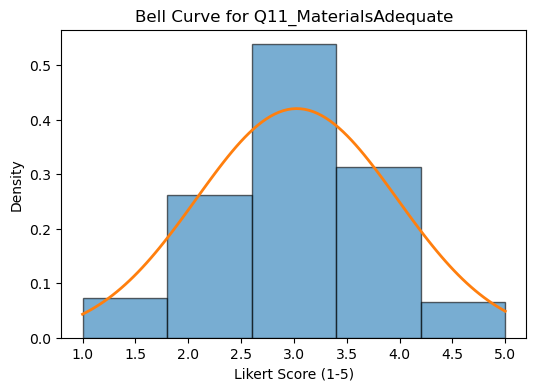

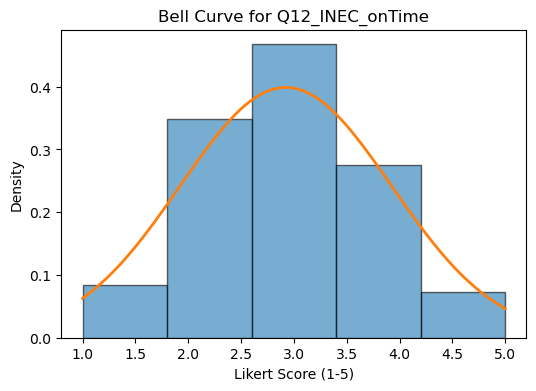

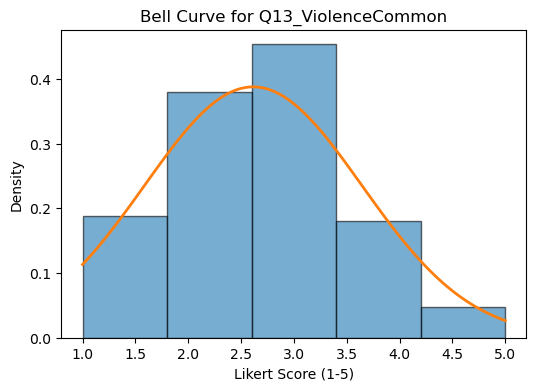

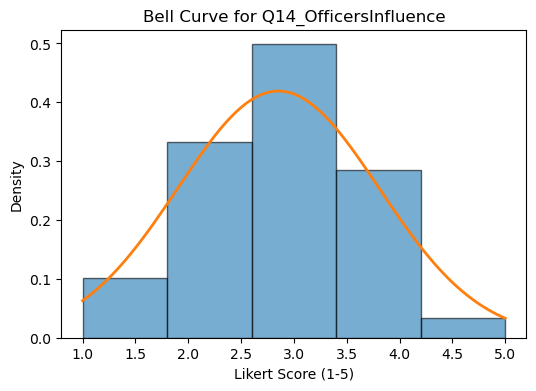

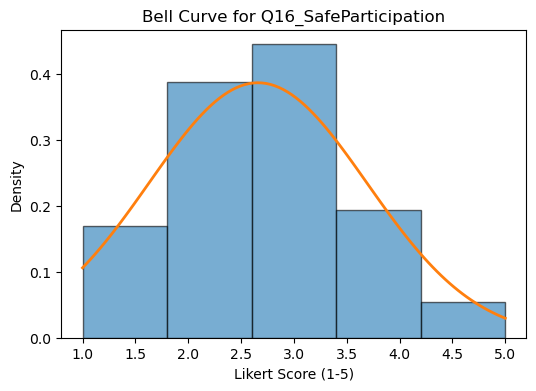

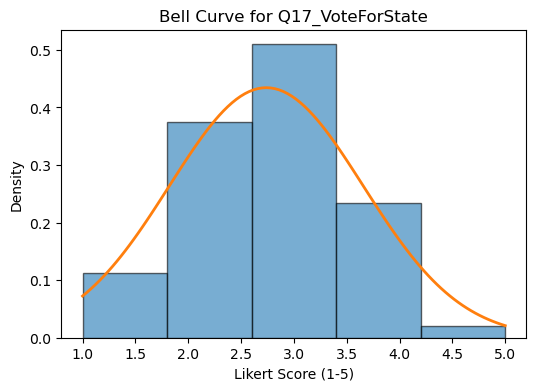

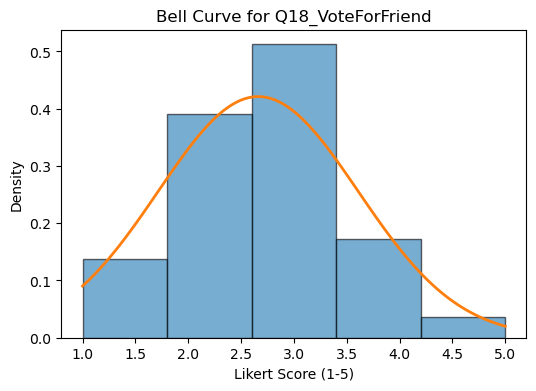

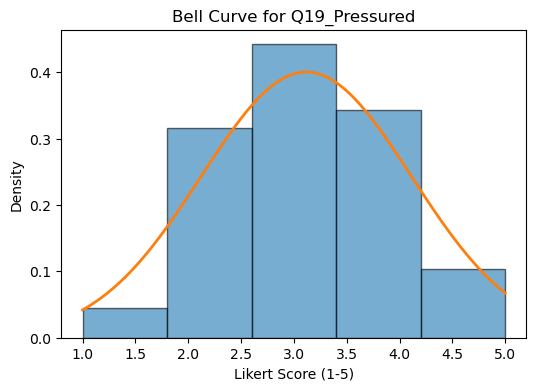

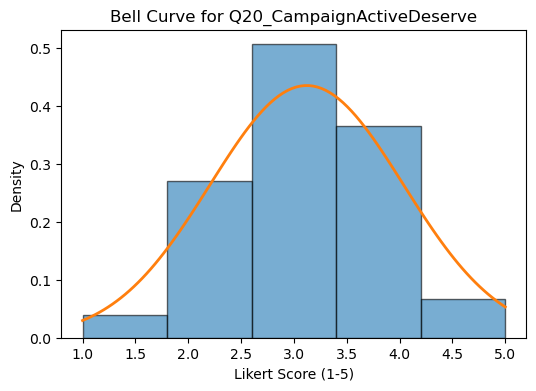

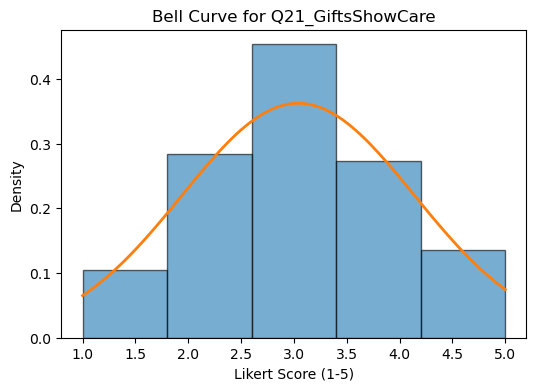

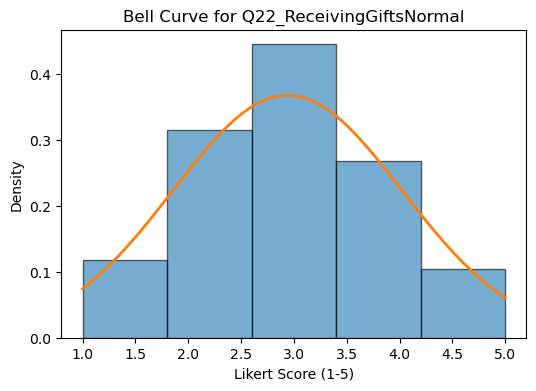

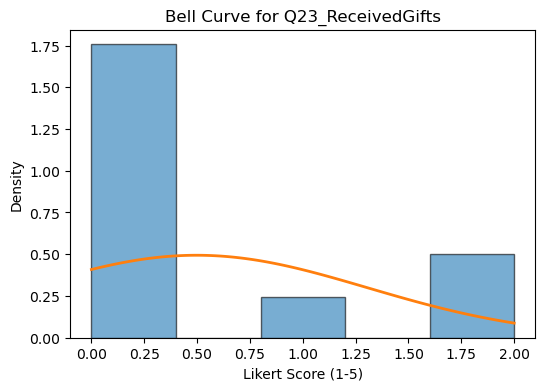

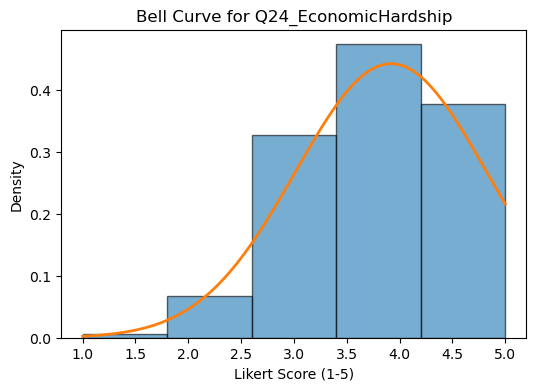

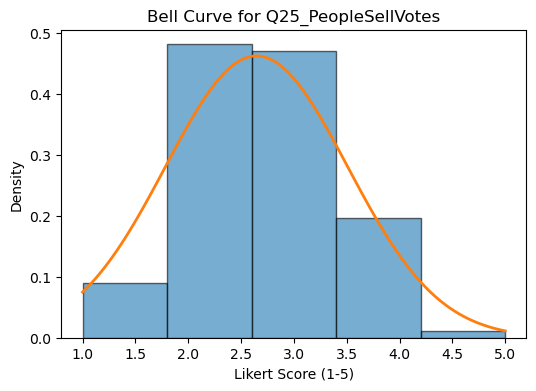

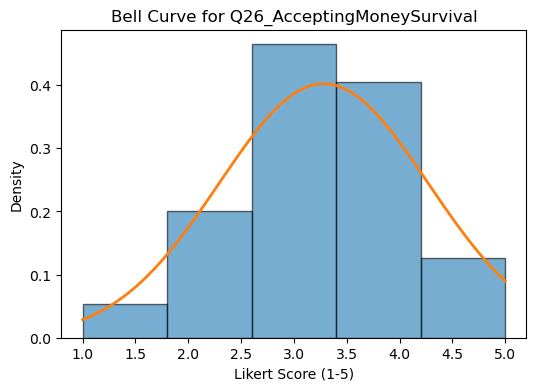

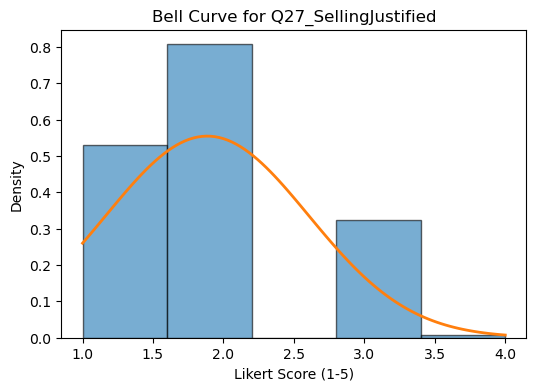

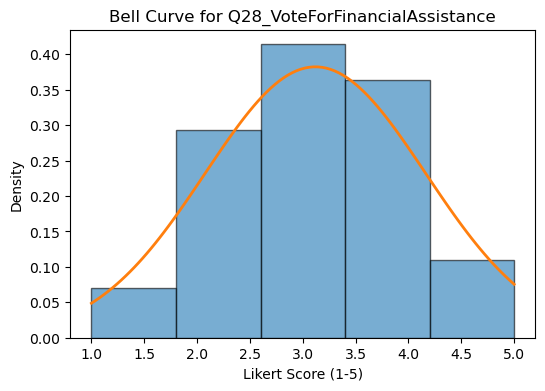

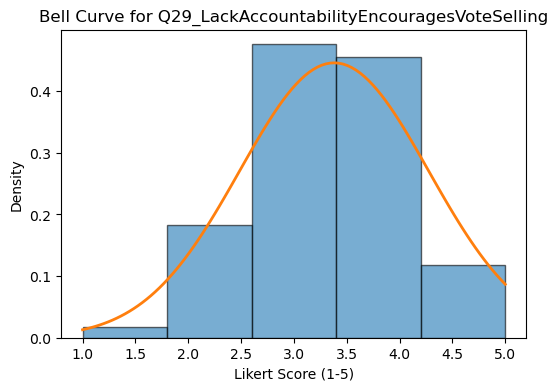

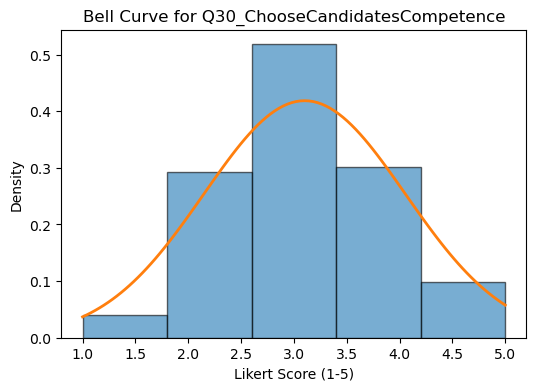

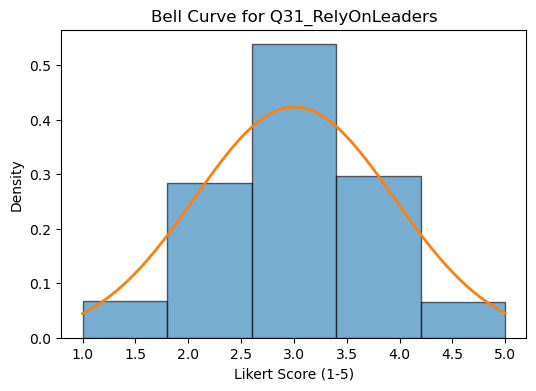

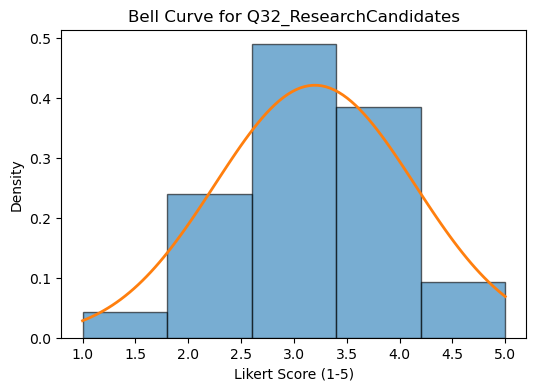

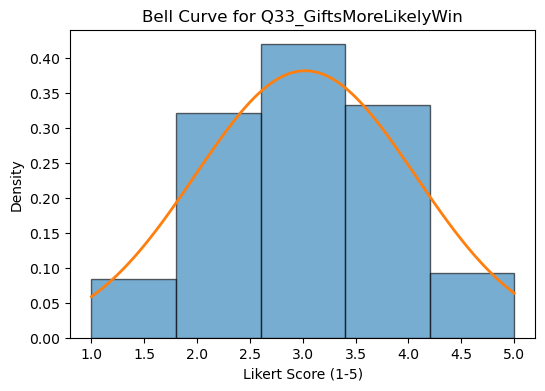

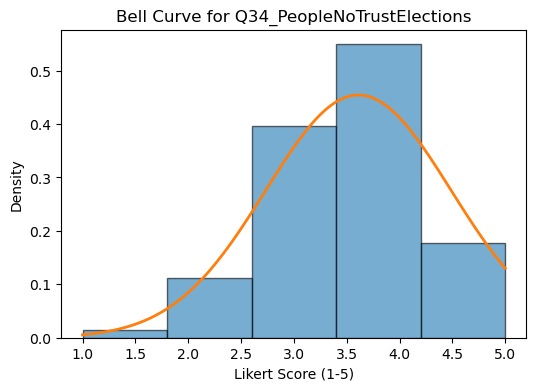

In [12]:
likert_cols = [c for c in df.columns if c.startswith("Q")]

for col in likert_cols:
    data = df[col]
    mu, sigma = data.mean(), data.std()
    x = np.linspace(data.min(), data.max(), 100)
    bell_curve = norm.pdf(x, mu, sigma)
    
    plt.figure(figsize=(6,4))
    plt.hist(data, bins=5, density=True, alpha=0.6, edgecolor='black')
    plt.plot(x, bell_curve, linewidth=2)
    plt.title(f"Bell Curve for {col}")
    plt.xlabel("Likert Score (1-5)")
    plt.ylabel("Density")
    plt.show()


### Categorical distributions

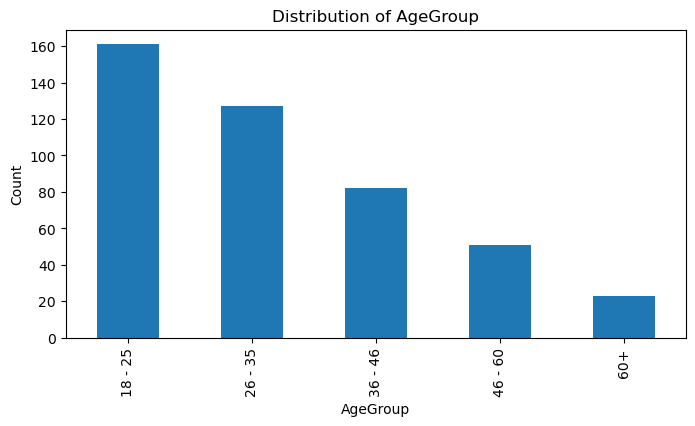

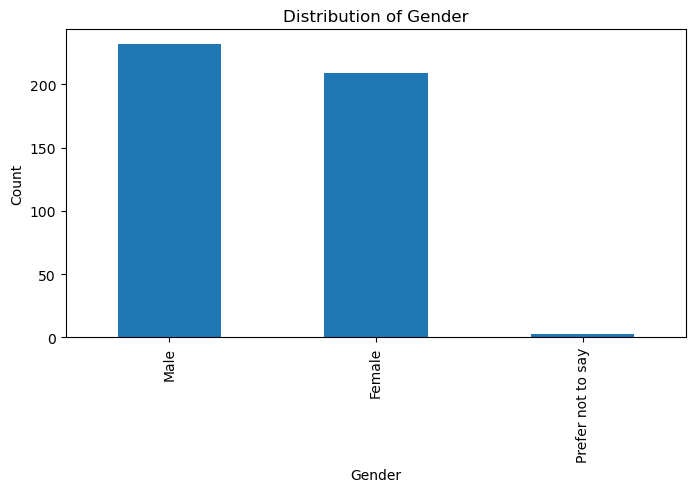

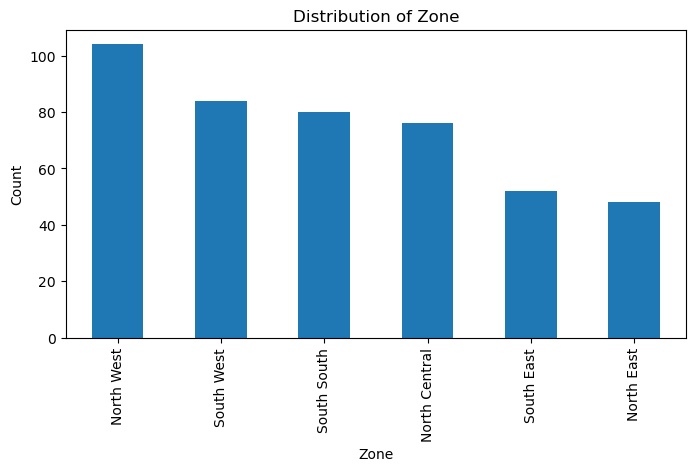

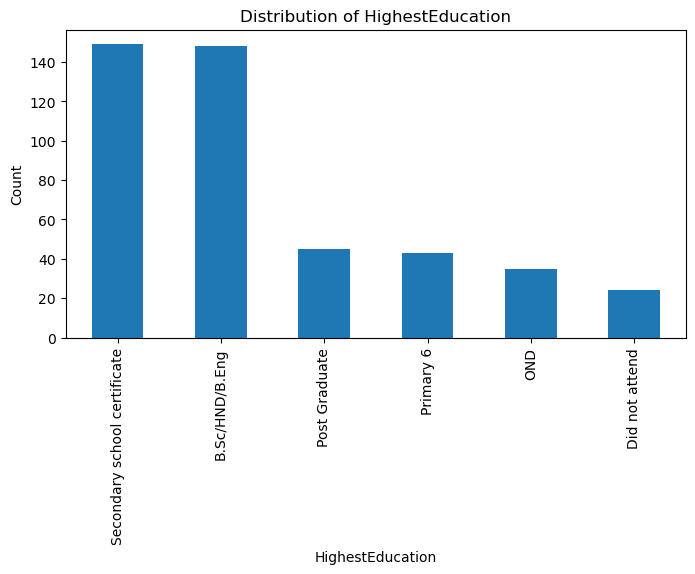

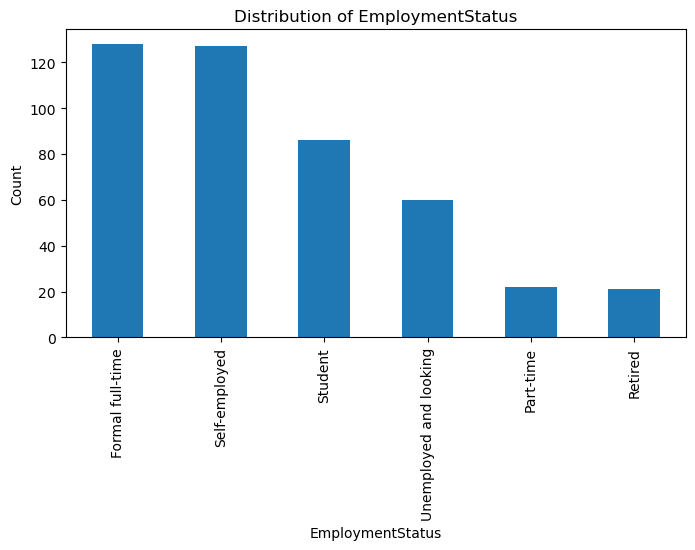

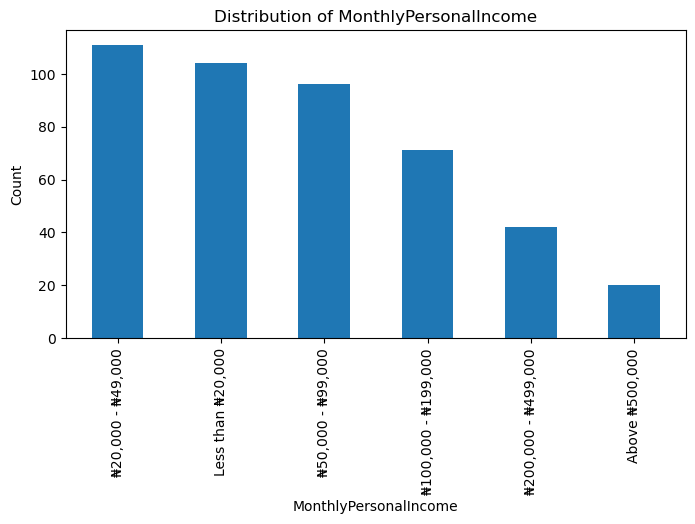

In [13]:
categorical_cols = ["AgeGroup", "Gender", "Zone", 
                    "HighestEducation", "EmploymentStatus", 
                    "MonthlyPersonalIncome"]

for col in categorical_cols:
    plt.figure(figsize=(8,4))
    df[col].value_counts().plot(kind='bar')
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()


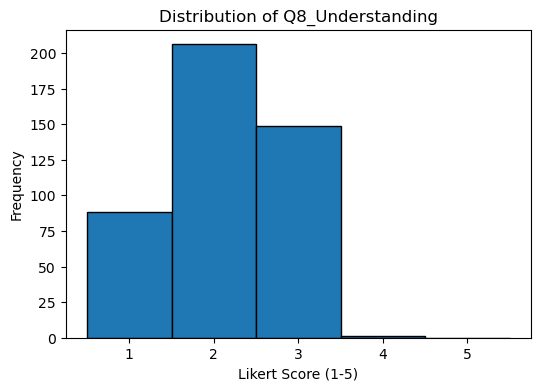

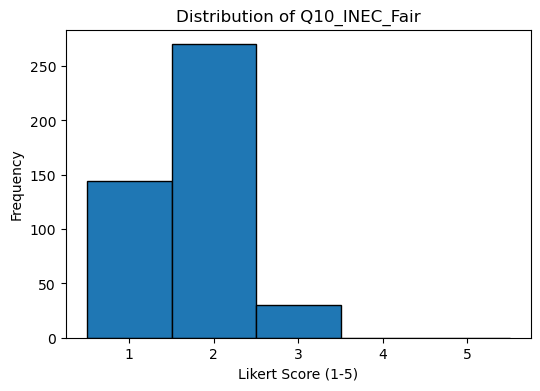

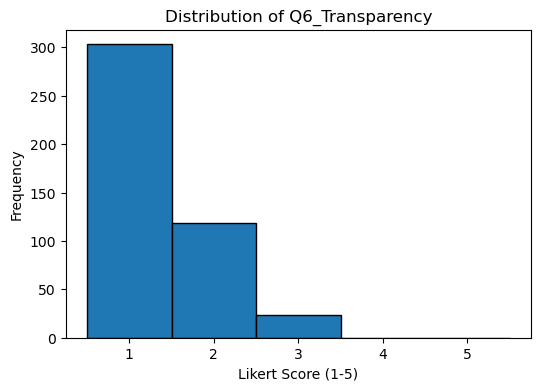

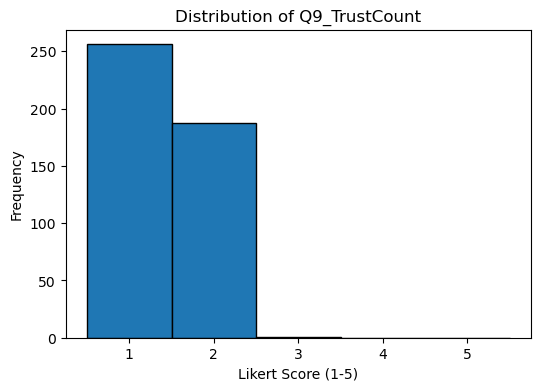

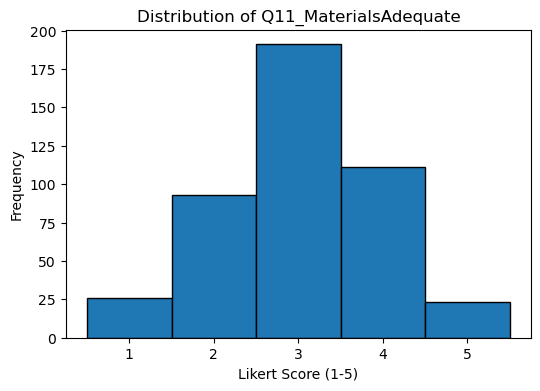

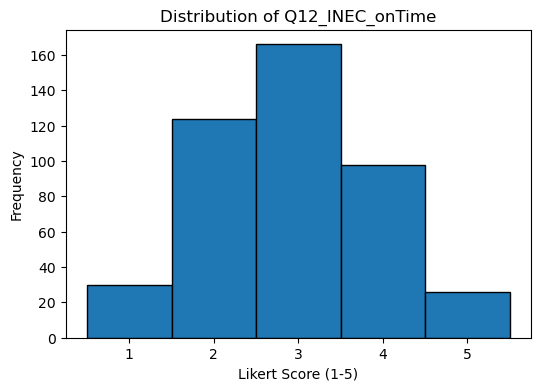

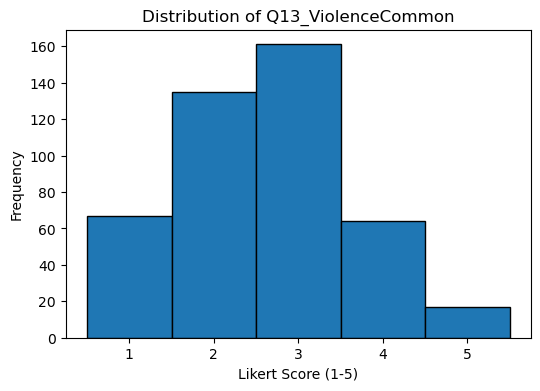

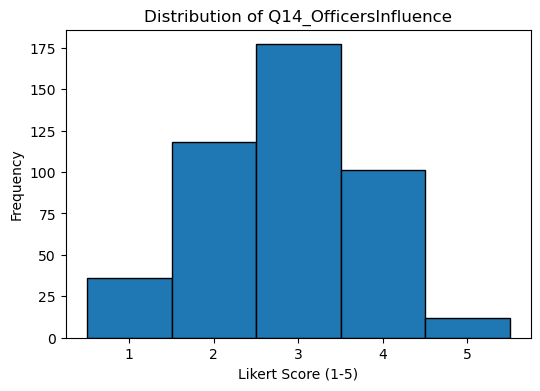

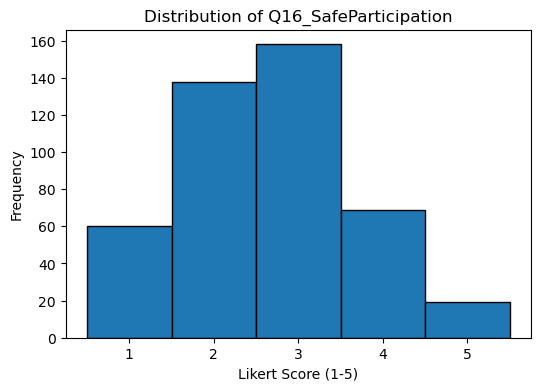

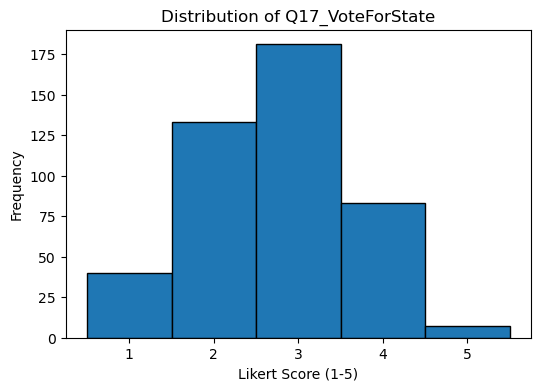

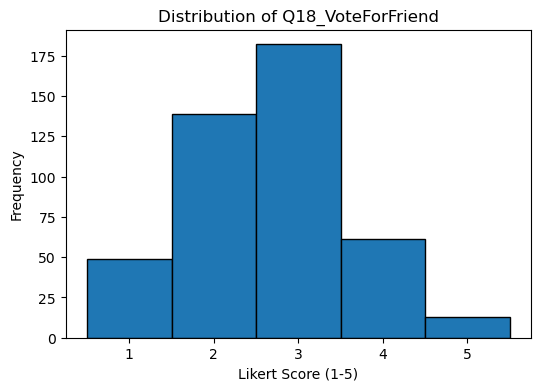

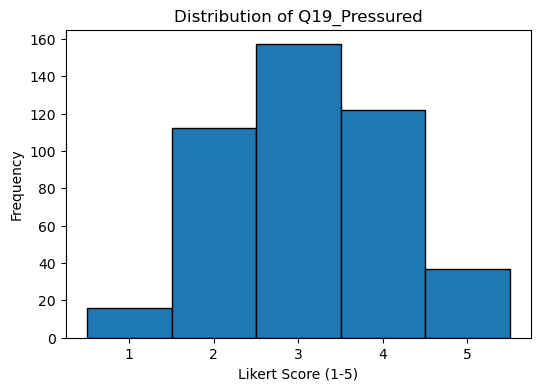

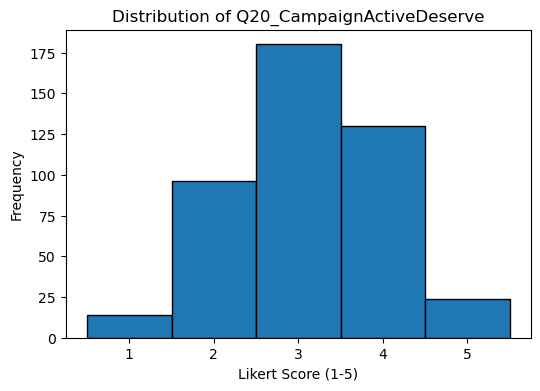

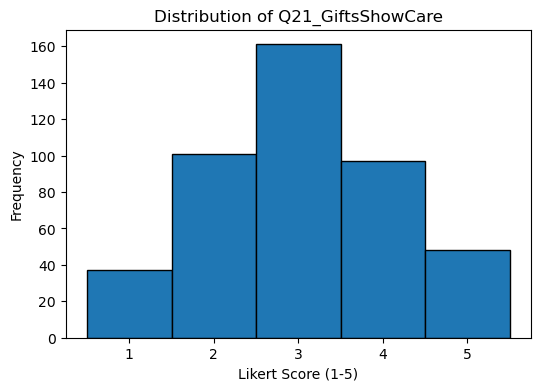

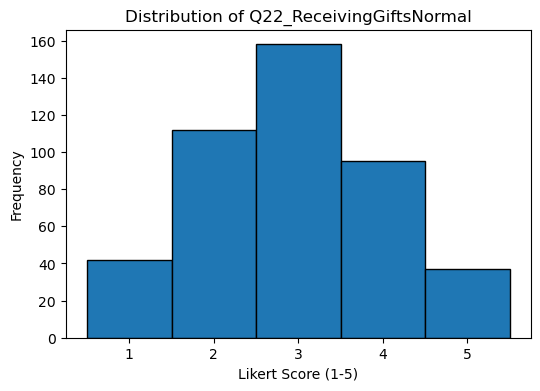

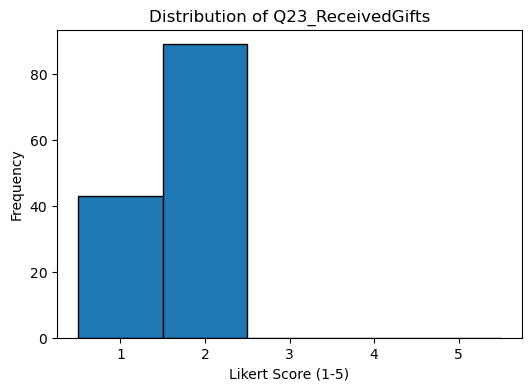

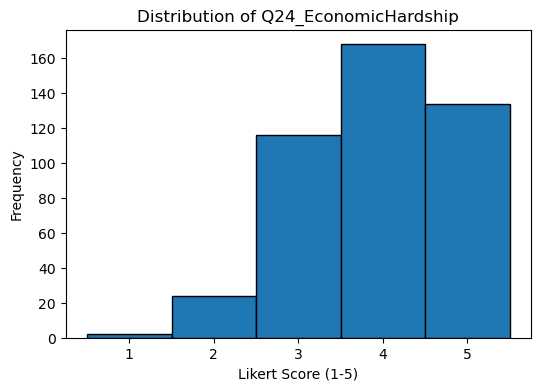

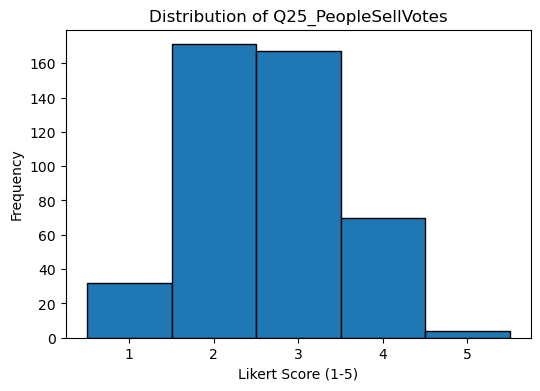

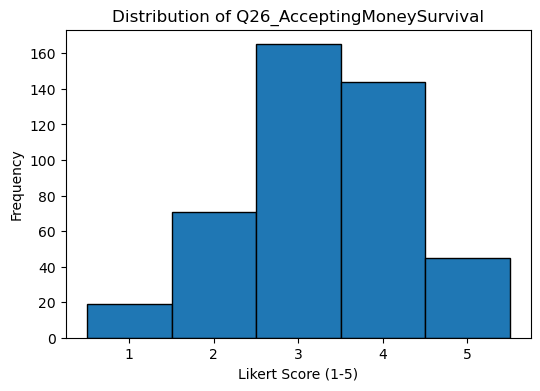

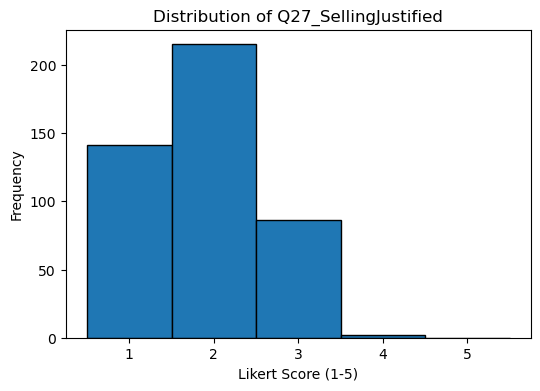

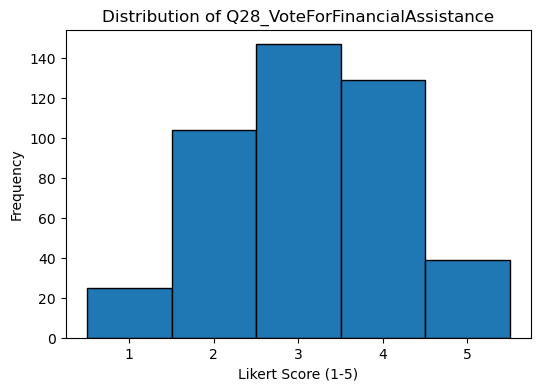

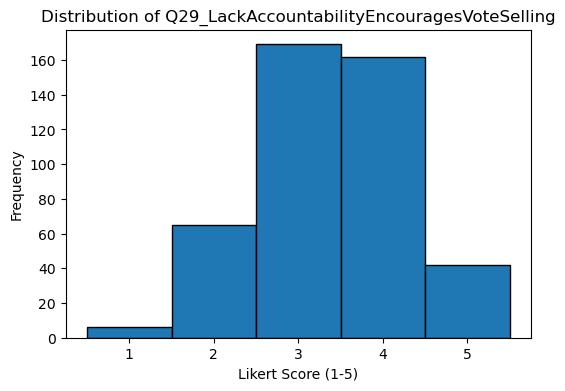

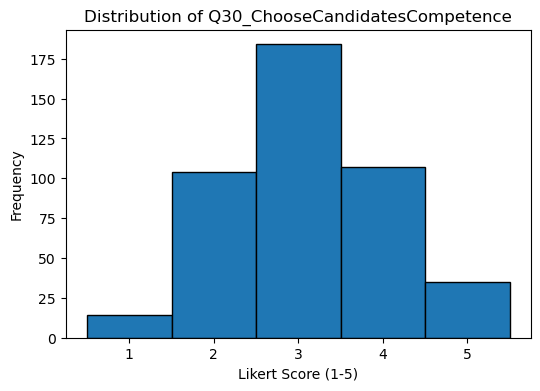

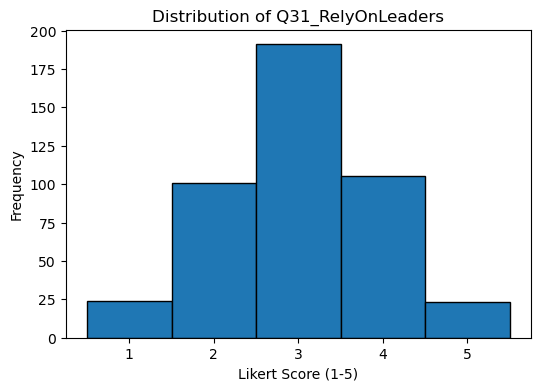

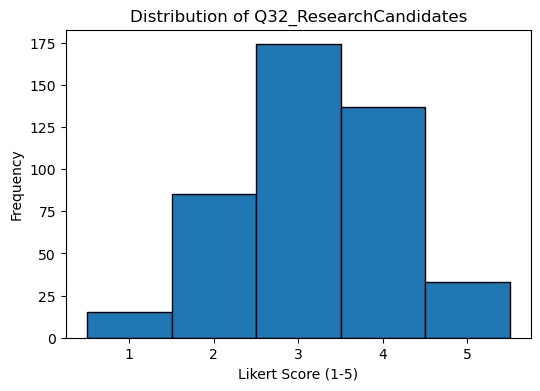

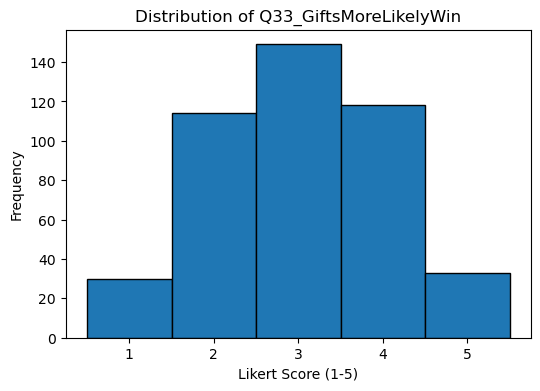

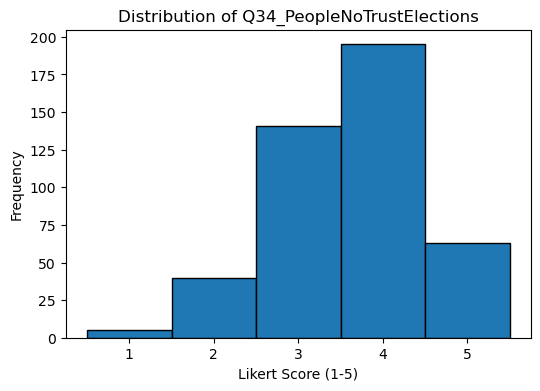

In [14]:
likert_cols = [c for c in df.columns if c.startswith("Q")]

for col in likert_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=np.arange(1,7)-0.5, edgecolor='black')
    plt.title(f"Distribution of {col}")
    plt.xlabel("Likert Score (1-5)")
    plt.ylabel("Frequency")
    plt.show()

## TARGET RELATIONSHIPS


Contingency table for AgeGroup:
 Target      0   1   2
AgeGroup             
18 - 25   112  21  28
26 - 35    96  12  19
36 - 46    57  14  11
46 - 60    42   3   6
60+        17   3   3


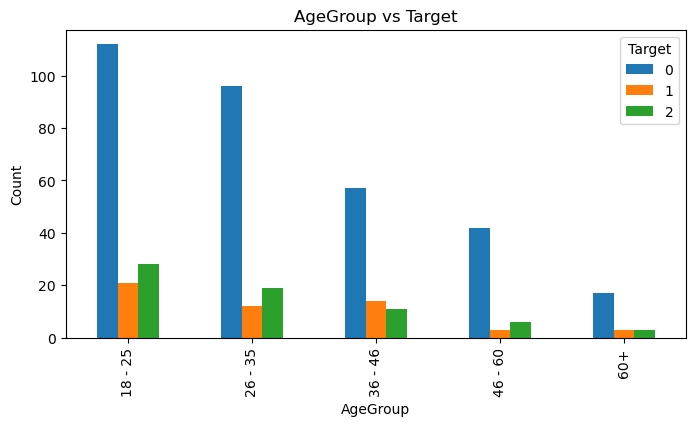


Contingency table for Gender:
 Target               0   1   2
Gender                        
Female             153  25  31
Male               169  28  35
Prefer not to say    2   0   1


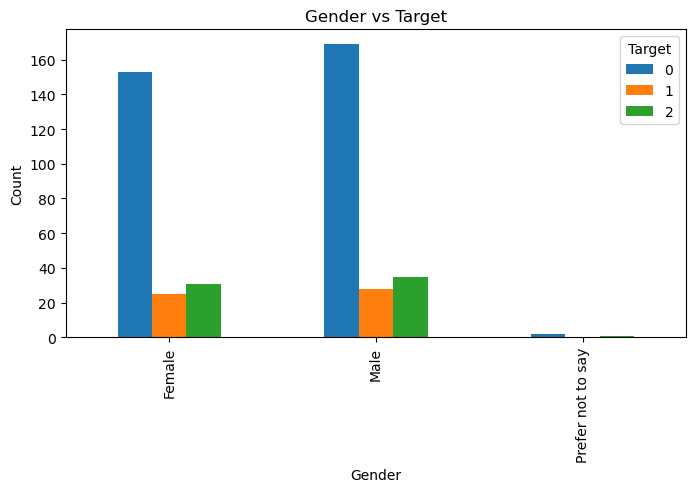


Contingency table for Zone:
 Target          0   1   2
Zone                     
North Central  53  10  13
North East     39   5   4
North West     81   8  15
South East     38   5   9
South South    51  16  13
South West     62   9  13


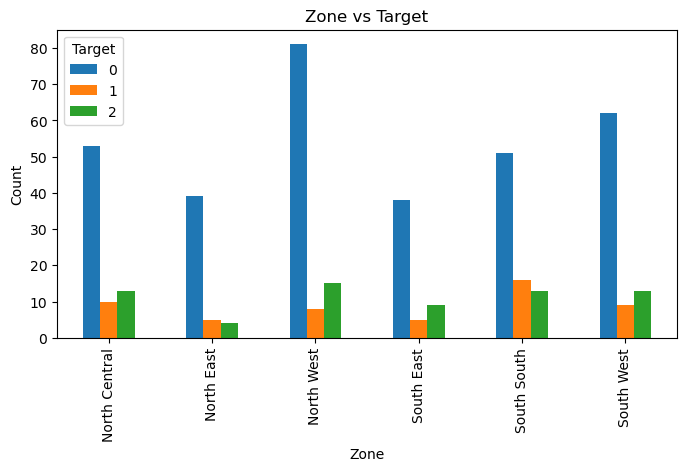


Contingency table for HighestEducation:
 Target                          0   1   2
HighestEducation                         
B.Sc/HND/B.Eng                114  11  23
Did not attend                 14   4   6
OND                            27   3   5
Post Graduate                  36   4   5
Primary 6                      26   8   9
Secondary school certificate  107  23  19


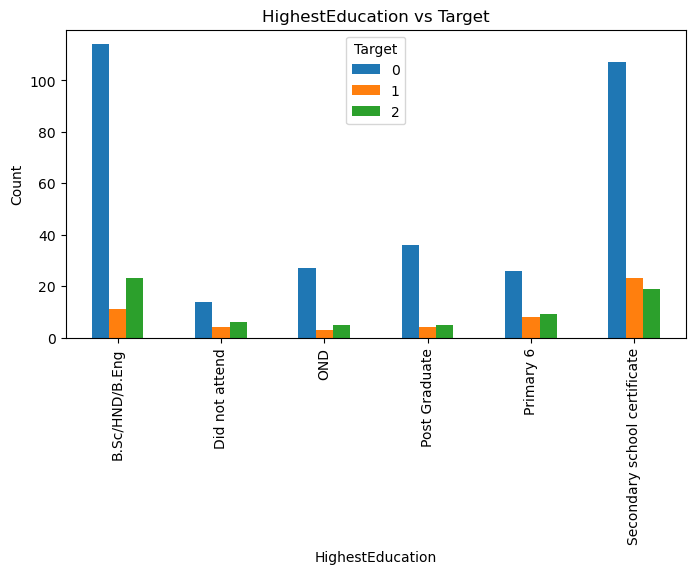


Contingency table for EmploymentStatus:
 Target                   0   1   2
EmploymentStatus                  
Formal full-time        91  18  19
Part-time               12   5   5
Retired                 17   0   4
Self-employed           91  17  19
Student                 64   9  13
Unemployed and looking  49   4   7


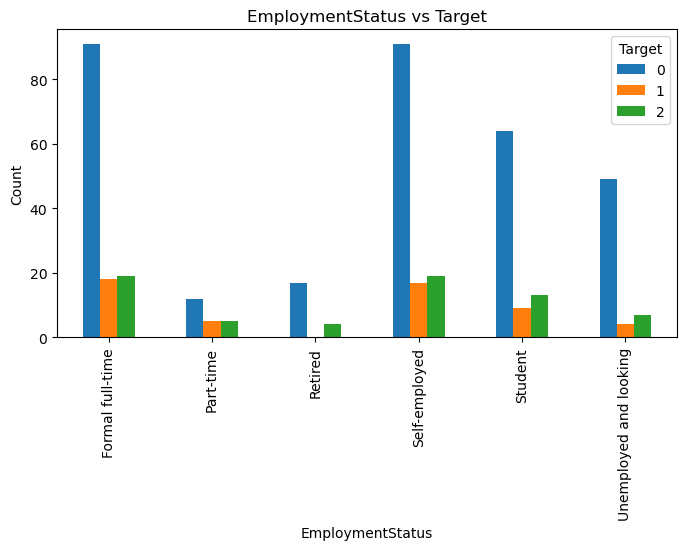


Contingency table for MonthlyPersonalIncome:
 Target                  0   1   2
MonthlyPersonalIncome            
Above ₦500,000         15   3   2
Less than ₦20,000      61   8  35
₦100,000 - ₦199,000    54  11   6
₦20,000 - ₦49,000      81  17  13
₦200,000 - ₦499,000    35   5   2
₦50,000 - ₦99,000      78   9   9


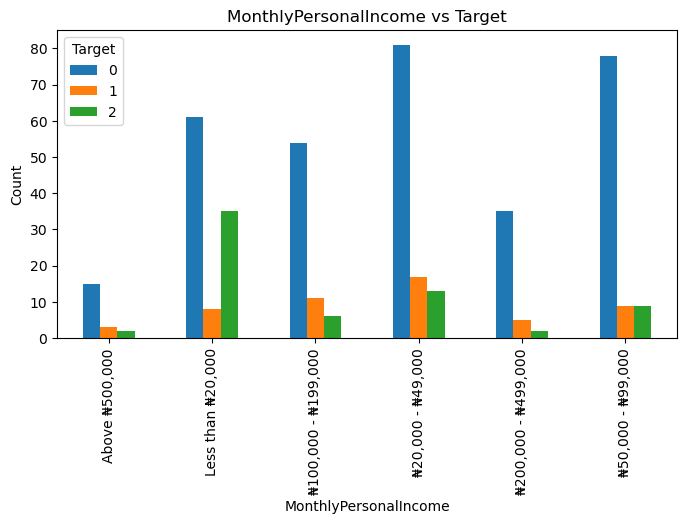

In [15]:
for col in categorical_cols:
    ct = pd.crosstab(df[col], df["Target"])
    print(f"\nContingency table for {col}:\n", ct)

    ct.plot(kind='bar', figsize=(8,4))
    plt.title(f"{col} vs Target")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()


<Figure size 600x400 with 0 Axes>

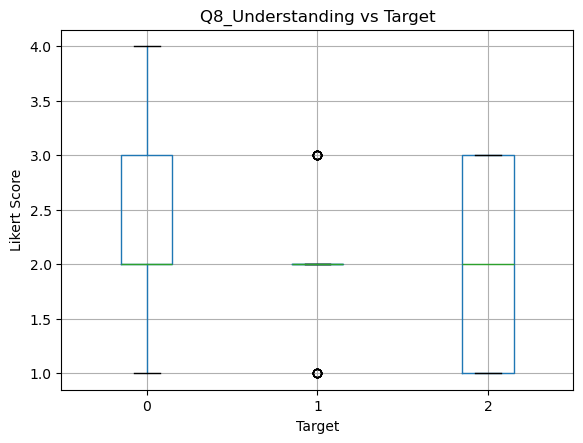

<Figure size 600x400 with 0 Axes>

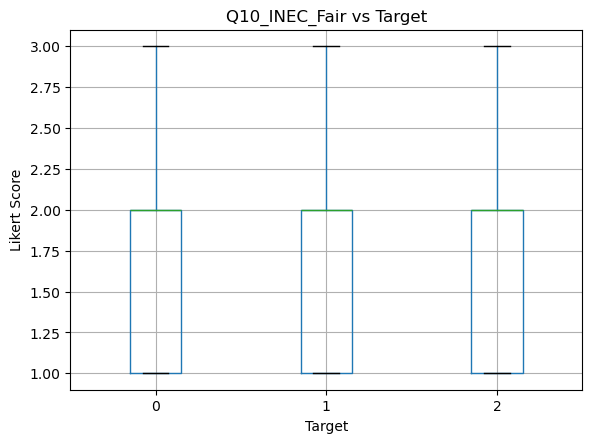

<Figure size 600x400 with 0 Axes>

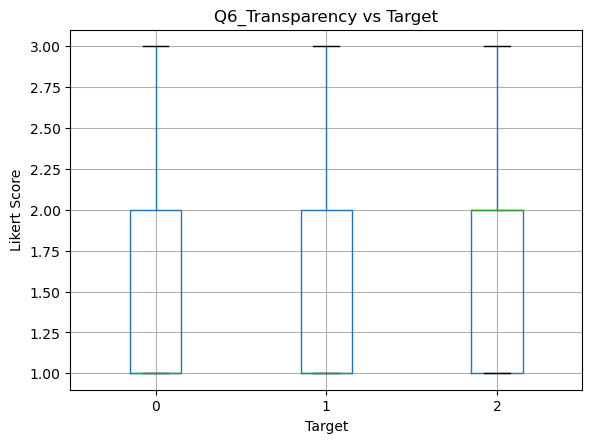

<Figure size 600x400 with 0 Axes>

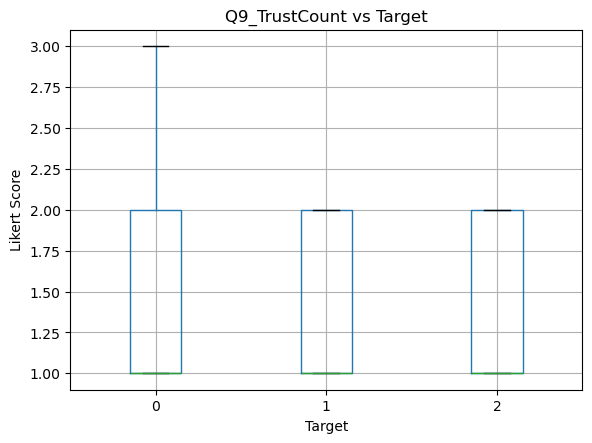

<Figure size 600x400 with 0 Axes>

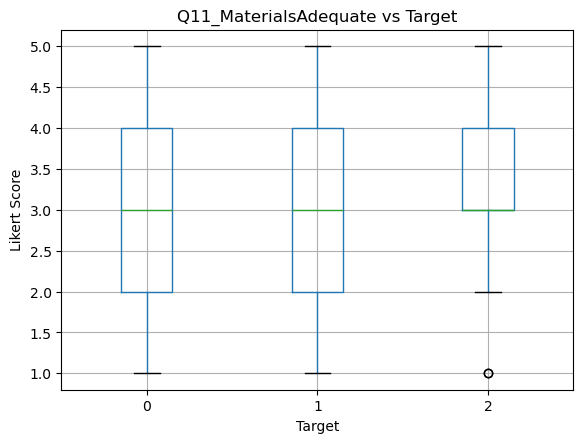

<Figure size 600x400 with 0 Axes>

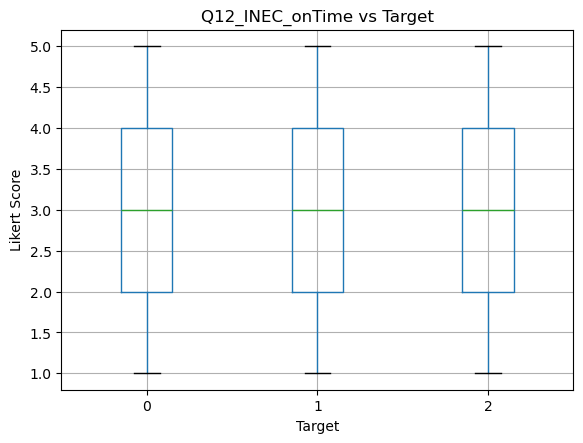

<Figure size 600x400 with 0 Axes>

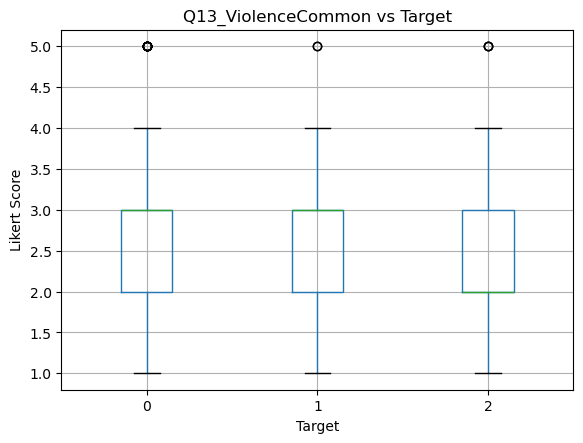

<Figure size 600x400 with 0 Axes>

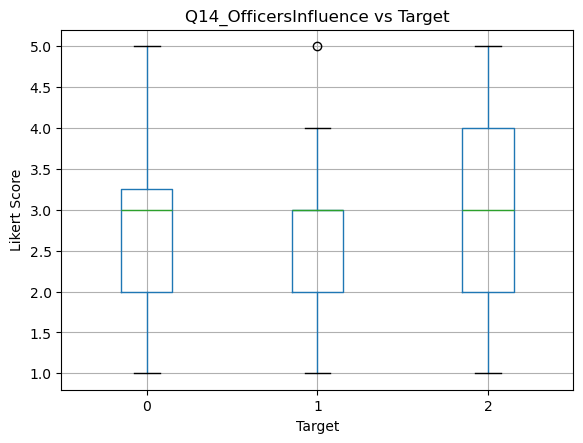

<Figure size 600x400 with 0 Axes>

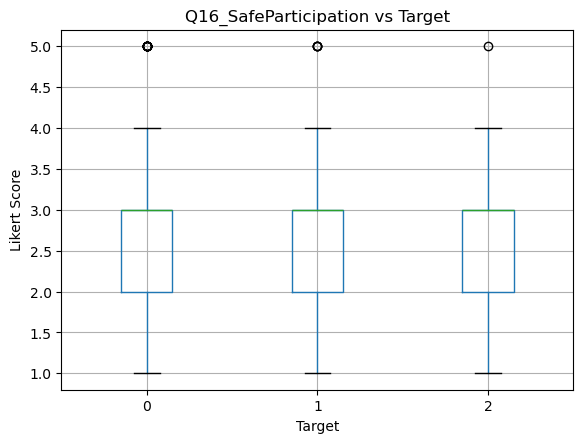

<Figure size 600x400 with 0 Axes>

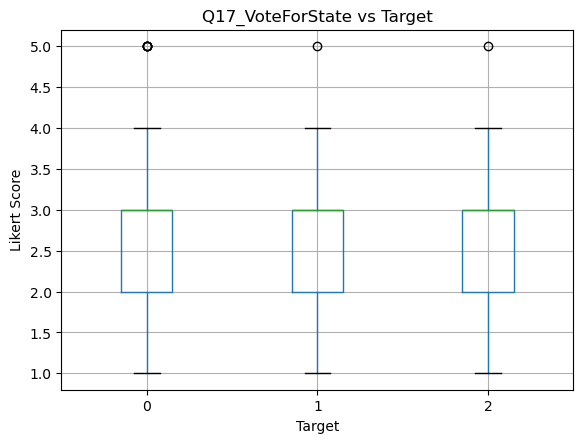

<Figure size 600x400 with 0 Axes>

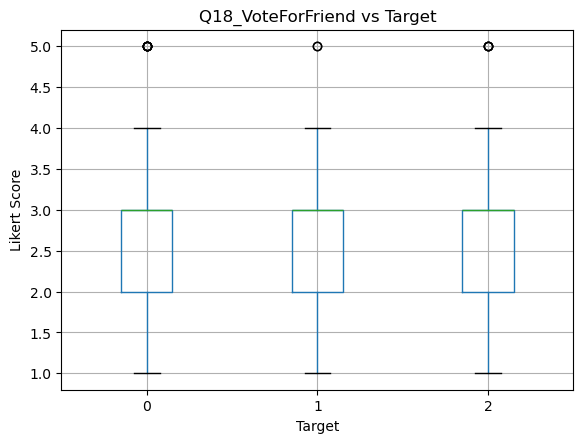

<Figure size 600x400 with 0 Axes>

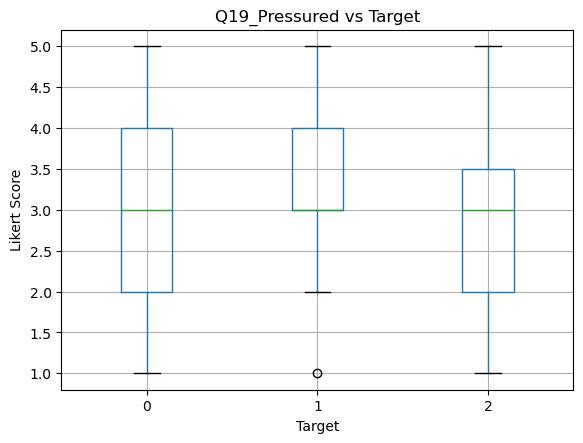

<Figure size 600x400 with 0 Axes>

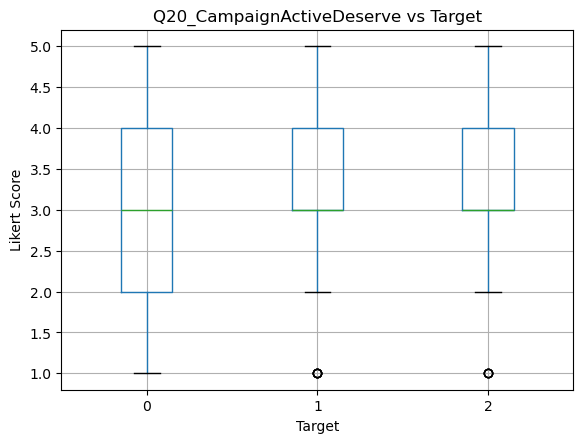

<Figure size 600x400 with 0 Axes>

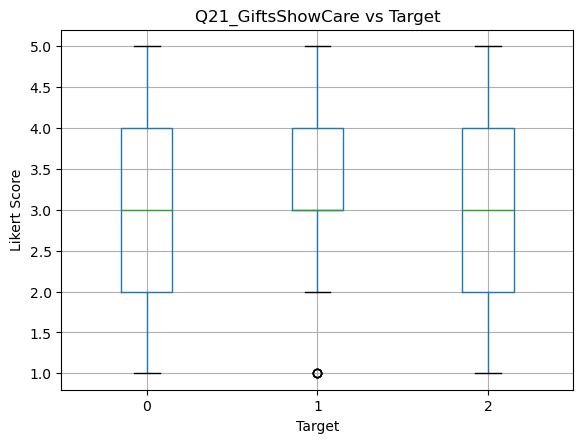

<Figure size 600x400 with 0 Axes>

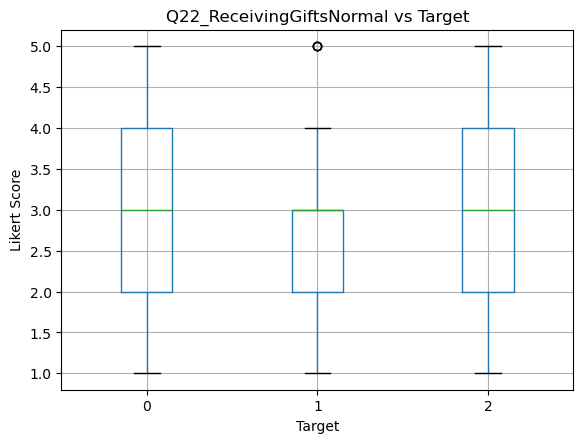

<Figure size 600x400 with 0 Axes>

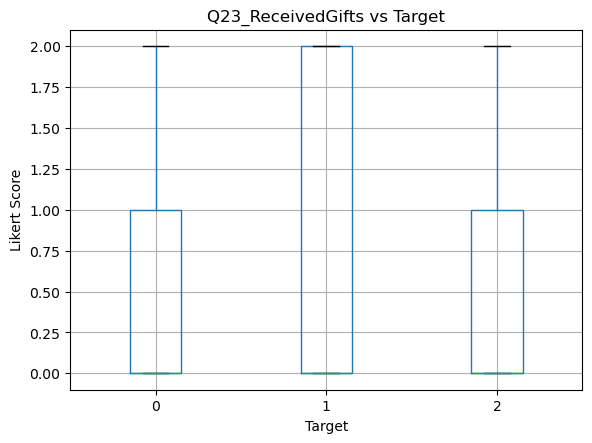

<Figure size 600x400 with 0 Axes>

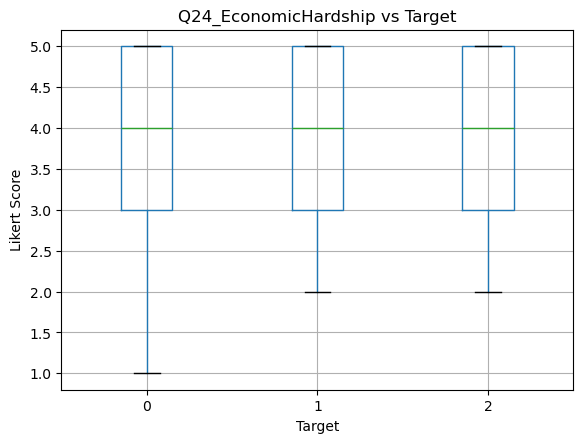

<Figure size 600x400 with 0 Axes>

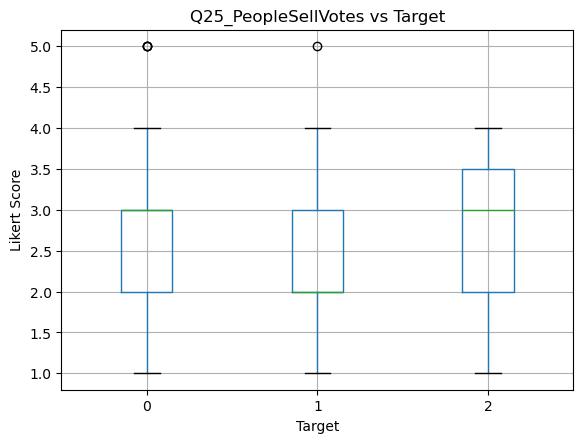

<Figure size 600x400 with 0 Axes>

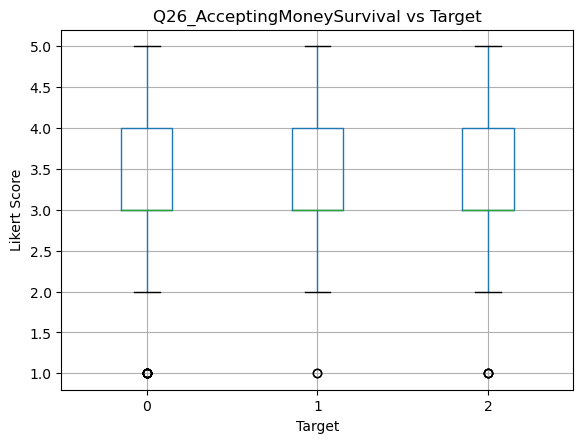

<Figure size 600x400 with 0 Axes>

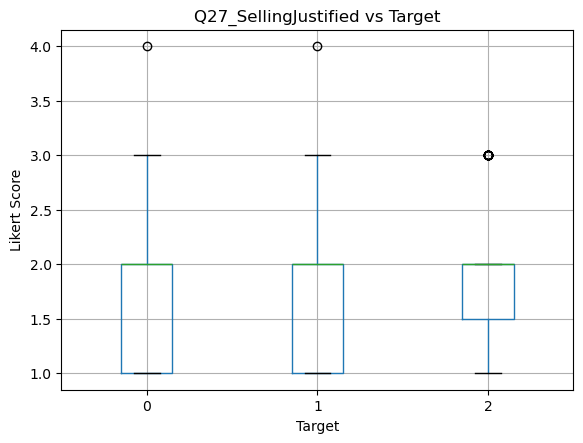

<Figure size 600x400 with 0 Axes>

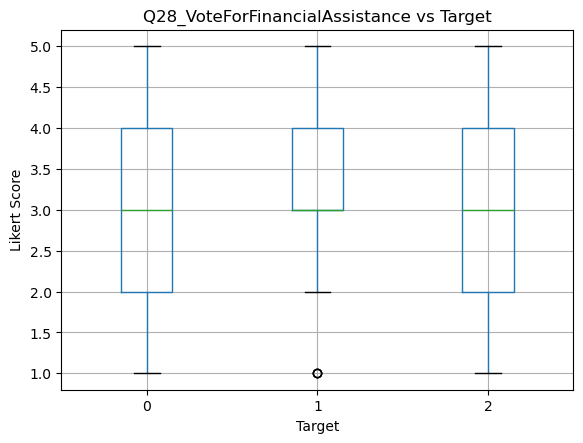

<Figure size 600x400 with 0 Axes>

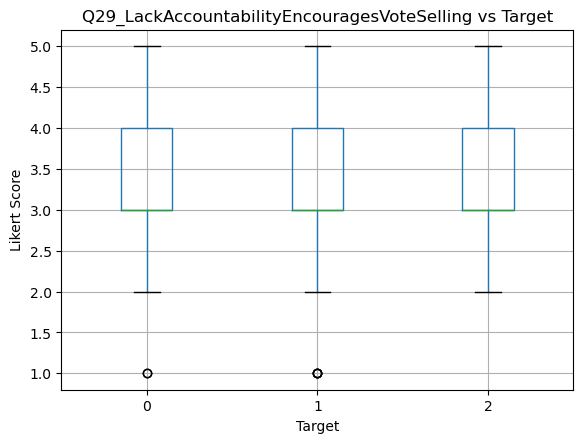

<Figure size 600x400 with 0 Axes>

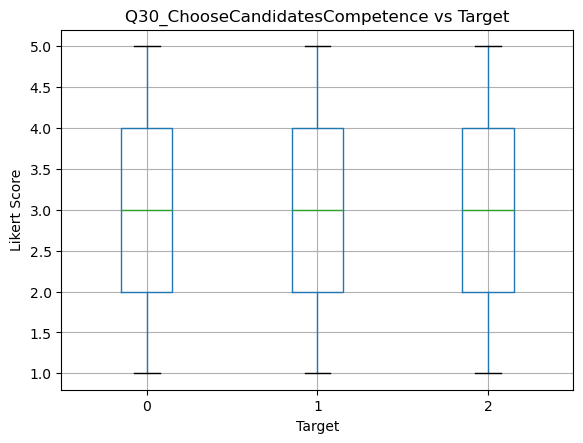

<Figure size 600x400 with 0 Axes>

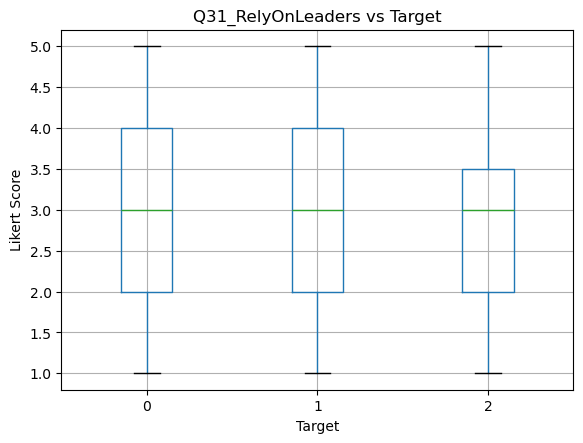

<Figure size 600x400 with 0 Axes>

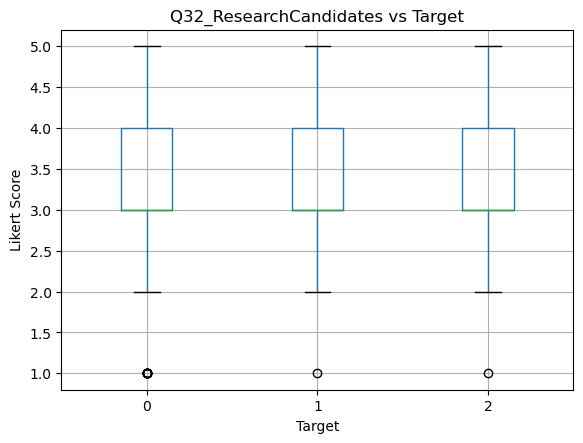

<Figure size 600x400 with 0 Axes>

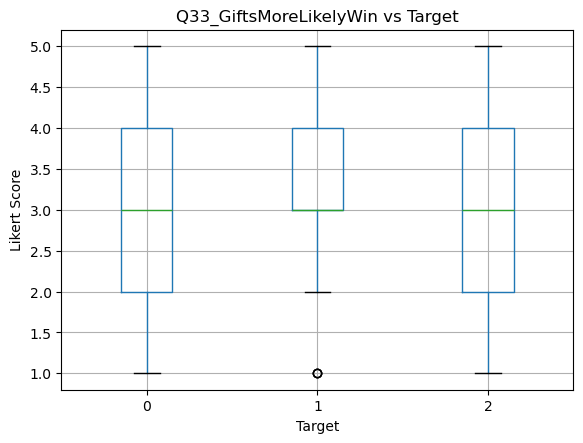

<Figure size 600x400 with 0 Axes>

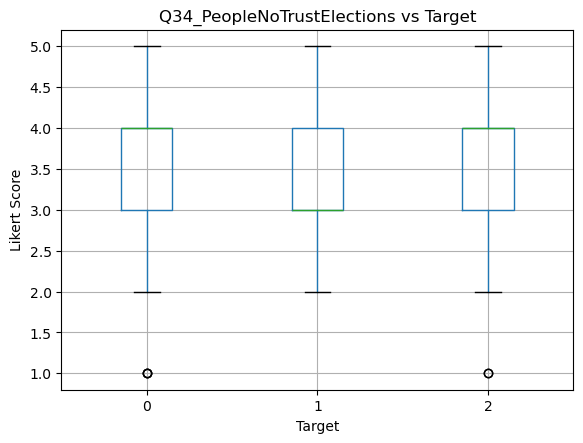

In [16]:
for col in likert_cols:
    plt.figure(figsize=(6,4))
    df.boxplot(column=col, by="Target")
    plt.title(f"{col} vs Target")
    plt.suptitle("")
    plt.xlabel("Target")
    plt.ylabel("Likert Score")
    plt.show()

## HYPOTHESIS TESTING

Understanding the behavioural and perceptual dynamics that influence electoral outcomes in Nigeria requires more than descriptive statistics; it requires empirical testing of the relationships between key variables. After the initial exploratory data analysis (EDA), several important patterns began to emerge from the dataset particularly concerning socioeconomic inequalities, regional disparities, institutional trust, and attitudes toward electoral integrity. These patterns were suggestive but not sufficient to draw defensible conclusions. Therefore, a structured set of hypotheses was developed to rigorously examine the strength, direction, and statistical significance of the observed relationships.

### H1: Income affects corruption exposure

In [17]:
corr, p = spearmanr(df["MonthlyPersonalIncome"], df["Q23_ReceivedGifts"])
print("H1 Spearman Income vs Receiving Gifts: corr=", corr, "p=", p)

H1 Spearman Income vs Receiving Gifts: corr= -0.17791191707053738 p= 0.00016431415747720818


### H2: Education reduces acceptance of vote buying

In [22]:
corr, p = spearmanr(df["HighestEducation"], df["Q26_AcceptingMoneySurvival"])
print("H2 Education vs Acceptance of Vote Buying: corr=", corr, "p=", p)


H2 Education vs Acceptance of Vote Buying: corr= 0.01314063895586959 p= 0.782454501024


### H3: Trust in INEC predicts distrust in elections

In [21]:
corr, p = spearmanr(df["Q10_INEC_Fair"], df["Q34_PeopleNoTrustElections"])
print("H3 INEC Trust vs Election Distrust: corr=", corr, "p=", p)


H3 INEC Trust vs Election Distrust: corr= -0.0661401440824862 p= 0.16414830187761767


### Chi-Square Tests for Categorical Independence
Zone × Target

In [23]:
table = pd.crosstab(df["Zone"], df["Target"])
chi2, p, dof, exp = chi2_contingency(table)
print("Zone vs Target Chi-square: chi2=", chi2, "p=", p)


Zone vs Target Chi-square: chi2= 10.235310902589333 p= 0.4200969928896386


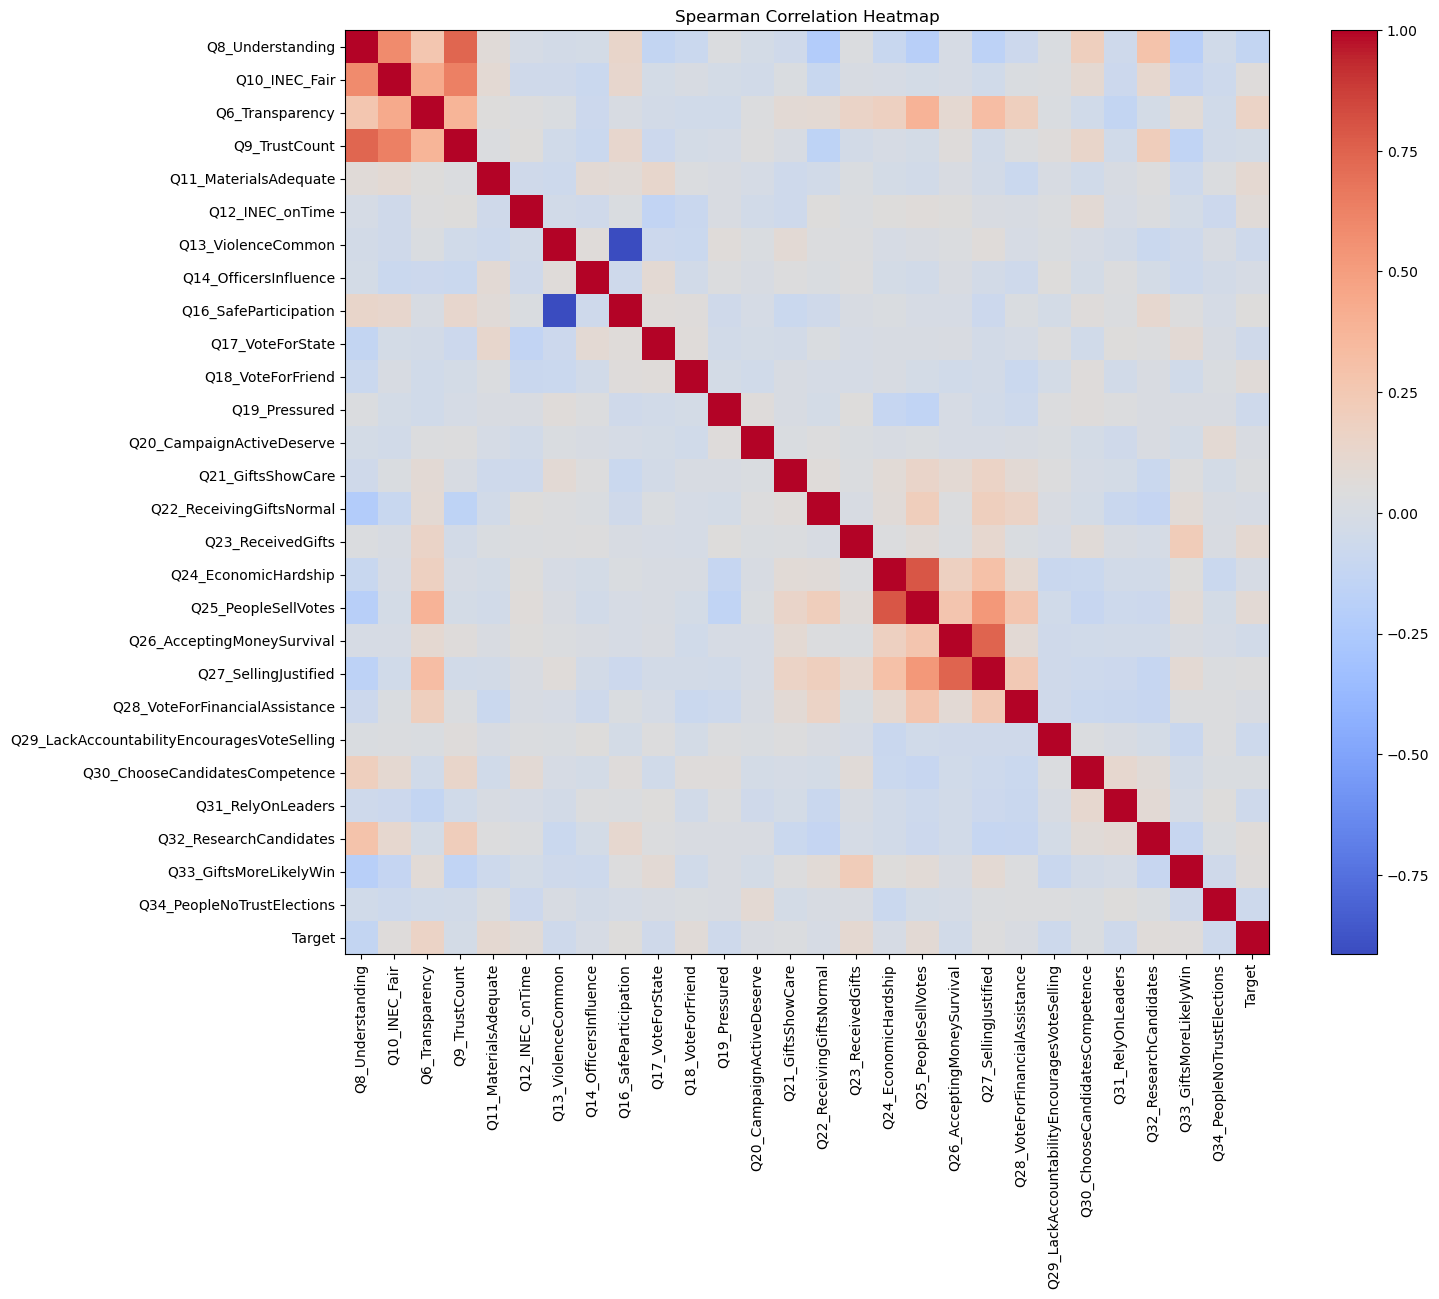

In [24]:
plt.figure(figsize=(16,12))
corr = df[likert_cols + ["Target"]].corr(method='spearman')

plt.imshow(corr, cmap='coolwarm', interpolation='nearest')
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Spearman Correlation Heatmap")
plt.show()
